# visualizations for COLOC results


In [124]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

sns.set_context("talk")
sns.set_style("white")


In [125]:
L2_colors = {
   'CD4T_Naive':   '#5A1C1C',  # deep brownish-maroon
   'CD4T_Memory':  '#752211',  # deep brick red (darker, less orange)
   'Treg':         '#C45F30',  # lighter burnt orange-brown (more rusty)
   'CD8T_Naive':   '#730000',  # wine red
   'CD8T_Memory':  '#C0392B',  # classic tomato red
   'gdT':          '#E1573A',  # warm coral red
   'MAIT':         '#FF8C42',  # vivid orange
   'NK_bright':    '#F48C06',  # golden orange
   'NK_dim':       '#D95F02',  # reddish orange
   'B_Memory': '#0B5F2F', 'B_Naive': '#2D9A57', 'B_atypical': '#40BD5C', 'Plasma': '#7FC685',
   'cDC1': '#16376A', 'cDC2': '#2B5CCD', 'pDC': '#4A85E3', 'cM': '#3E8599', 'ncM': '#65B0C4', 'Progen': '#595959', 'Prolif': '#9F7F66'
}

In [126]:
# Read in a gzipped dataframe
df=pd.read_csv("/gstore/data/ctgbioinfo/gordom14/ICC/data/coloc/L2/L2_coloc_accounting_data.csv.gz")
#df['Distance'] = df['Distance'].apply(lambda x: abs(x))

In [127]:
df.shape

(3533, 13)

In [128]:
df.head()

,Gene,Peak,Test,Posterior,chr,TSS,PeakCenter,Strand,Distance,absDistance,distanceCategory,Cell,Correlation
0,ENSG00000049247,chr1-7912993-7913493,PP.H4.abf,0.864172,chr1,7853512,7913243,-,-59731,59731,10-100kb,B_Memory,0.203651
1,ENSG00000064886,chr1-110787127-110787627,PP.H4.abf,0.790505,chr1,111200771,110787377,+,-413394,413394,100kb-1Mb,B_Memory,-0.021849
2,ENSG00000117481,chr1-46348018-46348518,PP.H4.abf,0.810709,chr1,46340177,46348268,+,8091,8091,0-10kb,B_Memory,-0.148611
3,ENSG00000117501,chr1-171252483-171252983,PP.H4.abf,0.997281,chr1,170935471,171252733,+,317262,317262,100kb-1Mb,B_Memory,0.305894
4,ENSG00000117597,chr1-209805958-209806458,PP.H4.abf,0.740107,chr1,209827972,209806208,+,-21764,21764,10-100kb,B_Memory,-0.204727


# basic coloc numbers

In [4]:
df[df['Posterior']>0.8]

,Gene,Peak,Test,Posterior,chr,TSS,PeakCenter,Strand,Distance,absDistance,distanceCategory,Cell,Correlation
0,ENSG00000049247,chr1-7912993-7913493,PP.H4.abf,0.864172,chr1,7853512,7913243,-,-59731,59731,10-100kb,B_Memory,0.203651
2,ENSG00000117481,chr1-46348018-46348518,PP.H4.abf,0.810709,chr1,46340177,46348268,+,8091,8091,0-10kb,B_Memory,-0.148611
3,ENSG00000117501,chr1-171252483-171252983,PP.H4.abf,0.997281,chr1,170935471,171252733,+,317262,317262,100kb-1Mb,B_Memory,0.305894
6,ENSG00000127603,chr1-39196791-39197291,PP.H4.abf,0.999696,chr1,39081316,39197041,+,115725,115725,100kb-1Mb,B_Memory,0.197751
7,ENSG00000143333,chr1-182633658-182634158,PP.H4.abf,0.999783,chr1,182604389,182633908,-,-29519,29519,10-100kb,B_Memory,0.332922
...,...,...,...,...,...,...,...,...,...,...,...,...,...
3528,ENSG00000128383,chr22-38967694-38968194,PP.H4.abf,0.946969,chr22,38952741,38967944,+,15203,15203,10-100kb,ncM,0.356682
3529,ENSG00000128383,chr22-38976484-38976984,PP.H4.abf,0.976126,chr22,38952741,38976734,+,23993,23993,10-100kb,ncM,0.199631
3530,ENSG00000128383,chr22-38977021-38977521,PP.H4.abf,0.899608,chr22,38952741,38977271,+,24530,24530,10-100kb,ncM,0.087631
3531,ENSG00000128383,chr22-38982082-38982582,PP.H4.abf,0.897537,chr22,38952741,38982332,+,29591,29591,10-100kb,ncM,0.351242


/local/tmp/ipykernel_28335/1833473400.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=cell_counts, x='Cell', y='log_count', palette=L2_colors)


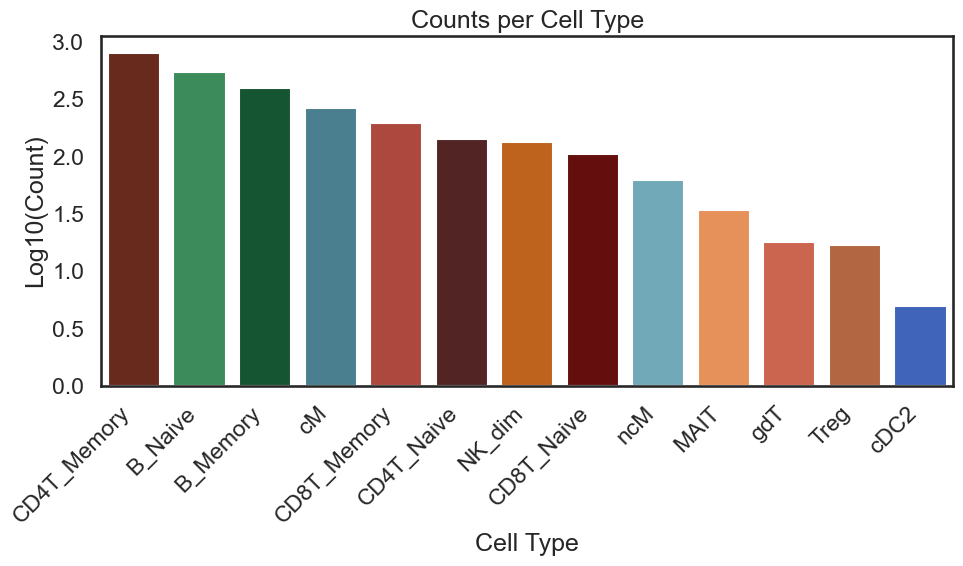

In [5]:
# Count the occurrences of each cell type
cell_counts = df[df['Posterior']>0.8]['Cell'].value_counts().reset_index()
cell_counts.columns = ['Cell', 'Count']
cell_counts['log_count']=np.log10(cell_counts['Count'] + 1)  # Adding 1 to avoid log(0)
# Create a barplot
plt.figure(figsize=(10, 6))
sns.barplot(data=cell_counts, x='Cell', y='log_count', palette=L2_colors)
plt.title('Counts per Cell Type')
plt.xlabel('Cell Type')
plt.ylabel('Log10(Count)')
plt.xticks(rotation=45, ha='right')  # ha='right' aligns text properly
plt.tight_layout() 
plt.savefig('/gstore/data/ctgbioinfo/gordom14/ICC/code/figures/coloc_cell_counts.png',dpi=300)  # Save as PNG
#plt.xticks(rotation=45)
plt.show()

# total counts for active/repressive

In [129]:
df['Correlation_Sign'] = df['Correlation'].apply(lambda x: 'Activating' if x > 0 else 'Repressive' if x < 0 else 'Zero')

In [130]:
df

,Gene,Peak,Test,Posterior,chr,TSS,PeakCenter,Strand,Distance,absDistance,distanceCategory,Cell,Correlation,Correlation_Sign
0,ENSG00000049247,chr1-7912993-7913493,PP.H4.abf,0.864172,chr1,7853512,7913243,-,-59731,59731,10-100kb,B_Memory,0.203651,Activating
1,ENSG00000064886,chr1-110787127-110787627,PP.H4.abf,0.790505,chr1,111200771,110787377,+,-413394,413394,100kb-1Mb,B_Memory,-0.021849,Repressive
2,ENSG00000117481,chr1-46348018-46348518,PP.H4.abf,0.810709,chr1,46340177,46348268,+,8091,8091,0-10kb,B_Memory,-0.148611,Repressive
3,ENSG00000117501,chr1-171252483-171252983,PP.H4.abf,0.997281,chr1,170935471,171252733,+,317262,317262,100kb-1Mb,B_Memory,0.305894,Activating
4,ENSG00000117597,chr1-209805958-209806458,PP.H4.abf,0.740107,chr1,209827972,209806208,+,-21764,21764,10-100kb,B_Memory,-0.204727,Repressive
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3528,ENSG00000128383,chr22-38967694-38968194,PP.H4.abf,0.946969,chr22,38952741,38967944,+,15203,15203,10-100kb,ncM,0.356682,Activating
3529,ENSG00000128383,chr22-38976484-38976984,PP.H4.abf,0.976126,chr22,38952741,38976734,+,23993,23993,10-100kb,ncM,0.199631,Activating
3530,ENSG00000128383,chr22-38977021-38977521,PP.H4.abf,0.899608,chr22,38952741,38977271,+,24530,24530,10-100kb,ncM,0.087631,Activating
3531,ENSG00000128383,chr22-38982082-38982582,PP.H4.abf,0.897537,chr22,38952741,38982332,+,29591,29591,10-100kb,ncM,0.351242,Activating


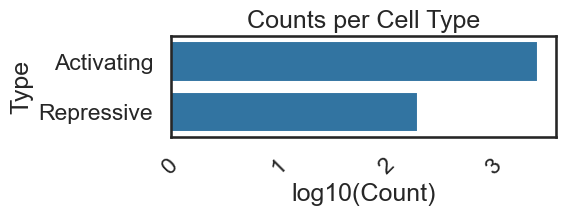

In [131]:

# Count the occurrences of each cell type
cell_counts = df[df['Posterior']>0.8]['Correlation_Sign'].value_counts().reset_index()
cell_counts.columns = ['Type', 'Count']
cell_counts['log_count'] = np.log10(cell_counts['Count'] + 1)  # Adding 1 to avoid log(0)
# Create a barplot
plt.figure(figsize=(6, 2.5))
sns.barplot(data=cell_counts, y='Type', x='log_count')
plt.title('Counts per Cell Type')
plt.ylabel('Type')
plt.xlabel('log10(Count)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('/gstore/data/ctgbioinfo/gordom14/ICC/code/figures/coloc_type_counts.png',dpi=300)  # Save as PNG
plt.show()

# total counts by TSS 

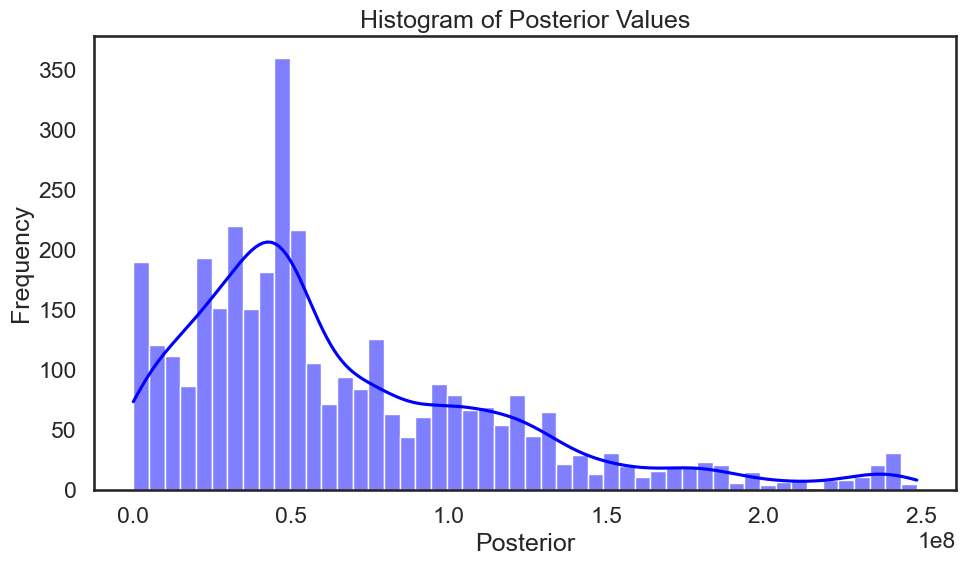

In [51]:
plt.figure(figsize=(10, 6))
sns.histplot(data=df, x='TSS', bins=50, kde=True, color='blue')
plt.title('Histogram of Posterior Values')
plt.xlabel('Posterior')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

In [65]:
min(df['absDistance'])

0

In [ ]:
import pandas as pd

# Create equal-width bins for TSS column
# Replace 'df' with your actual DataFrame variable name
#df['absDistance_bins'] = pd.cut(df['absDistance'], bins=4)  # Creates 10 equal-width bins with interval labels

# To see the bin ranges and counts
#print(df['absDistance_bins'].value_counts().sort_index())

# Create symmetrical bins around TSS position
#bin_size = 250000  # 250bp bins
max_distance = 1000000  # up to 2kb from TSS

#bin_edges = list(range(0, max_distance + bin_size, bin_size))
bin_edges = list([0,100000,250000,500000,1000000])
df['absDistance_bins'] = pd.cut(df['absDistance'], bins=bin_edges, labels=False)


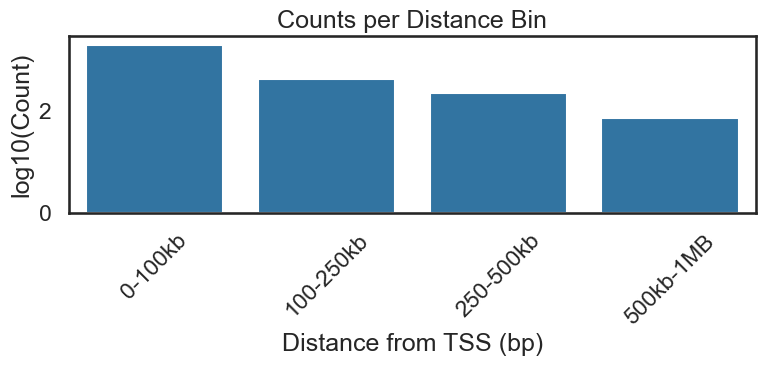

In [133]:
bin_edges = list([0,100000,250000,500000,1000000])
df['absDistance_bins'] = pd.cut(df['absDistance'], bins=bin_edges, labels=False)

cell_counts = pd.DataFrame(df[df['Posterior']>0.8]['absDistance_bins'].value_counts().reset_index())
cell_counts.columns = ['absDistance_bins', 'Count']
cell_counts['log_count']=np.log10(cell_counts['Count'] + 1)

plt.figure(figsize=(8, 4))  # Swapped dimensions too
sns.barplot(data=cell_counts, x='absDistance_bins', y='log_count')  # Swapped x and y
plt.title('Counts per Distance Bin')
plt.xlabel('Distance from TSS (bp)')
plt.ylabel('log10(Count)')
plt.xticks(ticks=[0,1,2,3], labels=['0-100kb','100-250kb','250-500kb','500kb-1MB'], rotation=45)
plt.tight_layout()
plt.savefig('/gstore/data/ctgbioinfo/gordom14/ICC/code/figures/coloc_dist_counts.png', dpi=300)
plt.show()

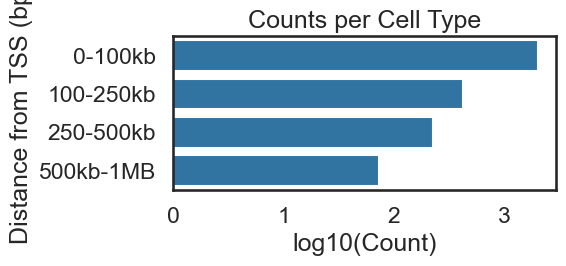

In [140]:
bin_edges = list([0,100000,250000,500000,1000000])
df['absDistance_bins'] = pd.cut(df['absDistance'], bins=bin_edges, labels=False)

cell_counts = pd.DataFrame(df[df['Posterior']>0.8]['absDistance_bins'].value_counts().reset_index())
#df['TSS_bins'].value_counts().sort_index()
cell_counts.columns = ['absDistance_bins', 'Count']
cell_counts['log_count']=np.log10(cell_counts['Count'] + 1)  # Adding 1 to avoid log(0)
cell_counts
plt.figure(figsize=(6, 3))
sns.barplot(data=cell_counts, y='absDistance_bins', x='log_count', orient='h')
plt.title('Counts per Cell Type')
plt.ylabel('Distance from TSS (bp)')
plt.xlabel('log10(Count)')
plt.yticks(ticks=[0,1,2,3],labels=['0-100kb','100-250kb','250-500kb','500kb-1MB'])#,rotation=90)
plt.tight_layout()
plt.savefig('/gstore/data/ctgbioinfo/gordom14/ICC/code/figures/coloc_dist_counts.png',dpi=300)  # Save as PNG
plt.show()

# COLOC total Histogram

In [152]:
def combine_coloc_results(cell_list,PPH=0.8):
    for cell in cell_list:
        cell_df = pd.read_csv(f"/gstore/data/ctgbioinfo/gordom14/ICC/data/coloc/L2/Pseudobulk/{cell}_coloc_pseudobulkcorrelation_data.csv.gz")
        cell_df=cell_df[(cell_df['Test']=='PP.H4.abf')]
        cell_df['Posterior_significance'] = (cell_df['Posterior'] > PPH).astype(int)
        cell_df['absCorrelation']= cell_df['Correlation'].abs()
        cell_df['Cell'] = cell
        if 'combined_df' in locals():
            combined_df = pd.concat([combined_df, cell_df], ignore_index=True)
        else:
            combined_df = cell_df
    return(combined_df)


In [153]:
cells=['B_Memory','B_Naive','CD4T_Memory','CD4T_Naive','CD8T_Memory',
       'CD8T_Naive','cDC2','cM','gdT','MAIT','ncM','NK_dim','Treg']

df=combine_coloc_results(cells,PPH=0.8)

In [154]:
df.head()

,Gene,Peak,Test,Posterior,chr,TSS,PeakCenter,Strand,Distance,Correlation,absCorrelation,absDistance,logDistance,Posterior_significance,Cell
0,ENSG00000049247,chr1-7912993-7913493,PP.H4.abf,8.641720e-01,chr1,7853512,7913243,-,-59731,0.203651,0.203651,59731,4.776200,1,B_Memory
1,ENSG00000049247,chr1-8424486-8424986,PP.H4.abf,1.537267e-04,chr1,7853512,8424736,-,-571224,0.114986,0.114986,571224,5.756806,0,B_Memory
2,ENSG00000057252,chr1-179365184-179365684,PP.H4.abf,5.864188e-08,chr1,179293714,179365434,+,71720,-0.009764,0.009764,71720,4.855640,0,B_Memory
3,ENSG00000057252,chr1-180003215-180003715,PP.H4.abf,2.648811e-02,chr1,179293714,180003465,+,709751,0.035581,0.035581,709751,5.851106,0,B_Memory
4,ENSG00000057252,chr1-180041524-180042024,PP.H4.abf,5.320329e-02,chr1,179293714,180041774,+,748060,0.002123,0.002123,748060,5.873936,0,B_Memory


In [155]:
df['Posterior'].min()

np.float64(2.95848062284714e-87)

In [156]:
df[df['Posterior_significance']==1]['Posterior'].min()

np.float64(0.800637213209071)

/local/tmp/ipykernel_6791/2555102603.py:6: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend().remove()


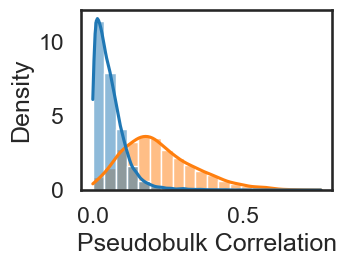

In [166]:
plt.figure(figsize=(4, 3))
sns.histplot(data=df, x='absCorrelation', hue='Posterior_significance', stat='density',bins=20, kde=True, common_norm=False)
#plt.title('Histogram of Posterior Values')
plt.xlabel('Pseudobulk Correlation')
#plt.ylabel('Frequency')
plt.legend().remove() 
#plt.ylim(0, 2) 
plt.tight_layout()
plt.show()

/local/tmp/ipykernel_6791/3446357496.py:6: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')  # Right side


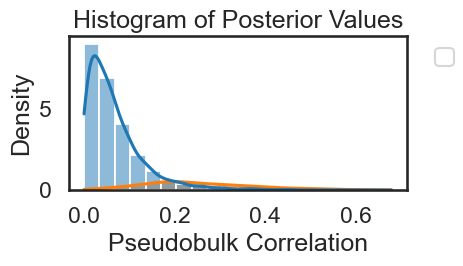

In [150]:
plt.figure(figsize=(5, 3))
sns.histplot(data=df[df['Cell']=='B_Naive'], x='absCorrelation', hue='Posterior_significance', stat='density',bins=20, kde=True)
plt.title('Histogram of Posterior Values')
plt.xlabel('Pseudobulk Correlation')
#plt.ylabel('Frequency')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')  # Right side
#plt.ylim(0, 2) 
plt.tight_layout()
plt.show()

In [ ]:
cell_counts = pd.DataFrame(df[df['Posterior']>0.8]['TSS_bins'].value_counts().reset_index())
